<a href="https://colab.research.google.com/github/chantika-maharani/ProyekAkhir_5C_Estimation-of-Obesity-Levels/blob/main/Notebook/03_Varian_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Varian 3: Eksperimen Pemilihan Subset Fitur & Profil Klaster (K-Means)


- **Kelas:** 5C
- **Paket Dataset:** 5C-8 — Estimation of Obesity Levels
- **Nama & NIM:** Chantika Maharani — 2488010080



Langkah 1 — Konfigurasi Varian 3

## Konfigurasi Varian 3:

* **Algoritma:** `KMeans` (`n_init=10`, `random_state=42`) untuk membandingkan tiga skenario *subset* fitur gaya hidup pada **`k = 5`** (acuan Varian 1) dan **`k = 6`** (acuan unggul Varian 2).
* **Data Masukan:** `data_preprocessed.csv` (2.087 baris, 9 kolom hasil *preprocessing*—fitur numerik `FCVC`, `FAF`, `TUE` sudah terstandarisasi, dan fitur kategorik `FAVC`, `CAEC` sudah di-*one-hot encode*). Kolom `NObeyesdad`, `Weight`, dan `Height` tidak digunakan agar bebas dari *data leakage*.
* **Tujuan:** Membandingkan **Skenario A** (semua 9 kolom *preprocessing*), **Skenario B** (pola makan: `FCVC`, `FAVC`, `CAEC`), dan **Skenario C** (aktivitas & layar: `FAF`, `TUE`), menyusun profil serta penamaan tiap klaster, dan menyimpan **Skenario A (`k = 6`)** sebagai model utama Varian 3 (`model_varian_3_kmeans.pkl`).

In [68]:
RANDOM_STATE = 42
N_INIT = 10
K_ACUAN = [5, 6]
K_MODEL_UTAMA = 6

print("Konfigurasi Varian 3 siap | K acuan:", K_ACUAN, "| Model utama: Skenario A (k=6)")

print("Konfigurasi Varian 3 siap | K acuan:", K_ACUAN, "| Model utama: Skenario A (k=5)")

Konfigurasi Varian 3 siap | K acuan: [5, 6] | Model utama: Skenario A (k=6)
Konfigurasi Varian 3 siap | K acuan: [5, 6] | Model utama: Skenario A (k=5)


Langkah 2 — Import Library & Muat data_preprocessed.csv

Memuat library yang diperlukan dan membaca data_preprocessed.csv (2.087 baris, 9 kolom). Karena fitur numeriknya sudah terstandarisasi (mean ≈ 0, std ≈ 1) dan fitur kategoriknya sudah berbentuk kolom one-hot, proses scaling tidak perlu diulang lagi.

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Muat data hasil preprocessing (bebas data leakage)
df_pre = pd.read_csv('data_preprocessed.csv').copy()

print("Ukuran data_preprocessed.csv:", df_pre.shape)
print("Total missing values:", df_pre.isna().sum().sum())
display(df_pre.head())

Ukuran data_preprocessed.csv: (2087, 9)
Total missing values: 0


,numerik__FCVC,numerik__FAF,numerik__TUE,kategori__FAVC_no,kategori__FAVC_yes,kategori__CAEC_Always,kategori__CAEC_Frequently,kategori__CAEC_Sometimes,kategori__CAEC_no
0,-0.788364,-1.186977,0.554211,1.0,0.0,0.0,0.0,1.0,0.0
1,1.082164,2.328908,-1.090505,1.0,0.0,0.0,0.0,1.0,0.0
2,-0.788364,1.156947,0.554211,1.0,0.0,0.0,0.0,1.0,0.0
3,1.082164,1.156947,-1.090505,1.0,0.0,0.0,0.0,1.0,0.0
4,-0.788364,-1.186977,-1.090505,1.0,0.0,0.0,0.0,1.0,0.0


Langkah 3 — Definisi Skenario Subset Fitur

Tiga skenario subset fitur disiapkan untuk melihat pengaruh pemilihan fitur terhadap kekompakan (Inertia) dan kualitas pemisahan klaster (Silhouette Score):

Skenario A: Semua 9 kolom hasil preprocessing (FCVC, FAF, TUE, serta one-hot FAVC dan CAEC).

Skenario B: Fokus pola makan (7 kolom one-hot FAVC & CAEC + numerik__FCVC).

Skenario C: Fokus aktivitas fisik & waktu layar (2 kolom: numerik__FAF, numerik__TUE).

In [70]:
skenario_prepo = {
    'Skenario A (Semua Fitur Prepo)': df_pre.columns.tolist(),
    'Skenario B (Pola Makan Prepo)': [
        'numerik__FCVC',
        'kategori__FAVC_no', 'kategori__FAVC_yes',
        'kategori__CAEC_Always', 'kategori__CAEC_Frequently',
        'kategori__CAEC_Sometimes', 'kategori__CAEC_no'
    ],
    'Skenario C (Aktivitas & Layar Prepo)': [
        'numerik__FAF', 'numerik__TUE'
    ]
}

for nama, cols in skenario_prepo.items():
    print(f"{nama}: {len(cols)} kolom")

Skenario A (Semua Fitur Prepo): 9 kolom
Skenario B (Pola Makan Prepo): 7 kolom
Skenario C (Aktivitas & Layar Prepo): 2 kolom


Langkah 4 — Eksperimen K-Means pada k = 5 dan k = 6

Setiap skenario dijalankan dengan KMeans(n_clusters=k, random_state=42, n_init=10) pada k = 5 dan k = 6, lalu hasilnya dirangkum dalam tabel Inertia dan Silhouette Score.

In [71]:
hasil_eksperimen = []
model_tersimpan = {}

for k_val in K_ACUAN:
    for nama_sken, cols in skenario_prepo.items():
        X = df_pre[cols].values
        km = KMeans(n_clusters=k_val, random_state=RANDOM_STATE, n_init=N_INIT)
        labels = km.fit_predict(X)
        sil = silhouette_score(X, labels)

        hasil_eksperimen.append({
            'k': k_val,
            'Skenario': nama_sken,
            'Jumlah_Kolom': len(cols),
            'Inertia': round(km.inertia_, 2),
            'Silhouette_Score': round(sil, 4)
        })
        model_tersimpan[(k_val, nama_sken)] = (km, labels, X)

df_eksperimen = pd.DataFrame(hasil_eksperimen)
display(df_eksperimen)

,k,Skenario,Jumlah_Kolom,Inertia,Silhouette_Score
0,5,Skenario A (Semua Fitur Prepo),9,3210.74,0.2883
1,5,Skenario B (Pola Makan Prepo),7,680.10,0.6391
2,5,Skenario C (Aktivitas & Layar Prepo),2,931.82,0.4174
3,6,Skenario A (Semua Fitur Prepo),9,2857.79,0.2924
4,6,Skenario B (Pola Makan Prepo),7,543.54,0.6703
5,6,Skenario C (Aktivitas & Layar Prepo),2,730.99,0.4583


Bagian 5 — Profil & Penamaan Klaster + Visualisasi Evaluasi

Grafik batang menampilkan perbandingan Silhouette Score dan Inertia antar-skenario pada k = 5 dan k = 6. Secara metrik, Skenario B (Pola Makan) mencatat Silhouette Score tertinggi (0,6391 pada k=5 dan 0,6703 pada k=6), sedangkan Skenario A menyatukan seluruh dimensi gaya hidup untuk profil yang lebih utuh.

In [72]:
fitur_k5 = ['FAVC_num', 'FCVC', 'CAEC_num', 'FAF', 'TUE']

ringkasan_profil = (
    df_profil_k5
    .groupby(['Cluster', 'Nama_Profil'])[fitur_k5]
    .agg(['count', 'mean'])
    .round(2)
)
display(ringkasan_profil)

FAVC_num        \
                                                              count  mean   
Cluster Nama_Profil                                                         
0       Penggemar Kalori Tinggi & Layar Tinggi                  428  1.00   
1       Penggemar Kalori Tinggi dengan Konsumsi Sayur T...      738  1.00   
2       Pola Camilan Sering (CAEC Tinggi)                       211  0.94   
3       Non-FAVC & Aktivitas Fisik Lebih Tinggi                 231  0.00   
4       Penggemar Kalori Tinggi dengan Waktu Layar Rendah       479  1.00   

                                                            FCVC        \
                                                           count  mean   
Cluster Nama_Profil                                                      
0       Penggemar Kalori Tinggi & Layar Tinggi               428  2.02   
1       Penggemar Kalori Tinggi dengan Konsumsi Sayur T...   738  2.92   
2       Pola Camilan Sering (CAEC Tinggi)                    211  2.42   
3       Non-FAVC & Aktivitas Fisik Lebih Tinggi              231  2.44   
4       Penggemar Kalori Tinggi dengan Waktu Layar Rendah    479  2.01   

                                                           CAEC_num        \
                                                              count  mean   
Cluster Nama_Profil                                                         
0       Penggemar Kalori Tinggi & Layar Tinggi                  428  1.02   
1       Penggemar Kalori Tinggi dengan Konsumsi Sayur T...      738  0.99   
2       Pola Camilan Sering (CAEC Tinggi)                       211  2.25   
3       Non-FAVC & Aktivitas Fisik Lebih Tinggi                 231  1.25   
4       Penggemar Kalori Tinggi dengan Waktu Layar Rendah       479  0.95   

                                                             FAF         TUE  \
                                                           count  mean count   
Cluster Nama_Profil                                                            
0       Penggemar Kalori Tinggi & Layar Tinggi               428  0.98   428   
1       Penggemar Kalori Tinggi dengan Konsumsi Sayur T...   738  0.99   738   
2       Pola Camilan Sering (CAEC Tinggi)                    211  1.10   211   
3       Non-FAVC & Aktivitas Fisik Lebih Tinggi              231  1.26   231   
4       Penggemar Kalori Tinggi dengan Waktu Layar Rendah    479  0.92   479   

                                                                  
                                                            mean  
Cluster Nama_Profil                                               
0       Penggemar Kalori Tinggi & Layar Tinggi              1.40  
1       Penggemar Kalori Tinggi dengan Konsumsi Sayur T...  0.59  
2       Pola Camilan Sering (CAEC Tinggi)                   0.69  
3       Non-FAVC & Aktivitas Fisik Lebih Tinggi             0.55  
4       Penggemar Kalori Tinggi dengan Waktu Layar Rendah   0.15

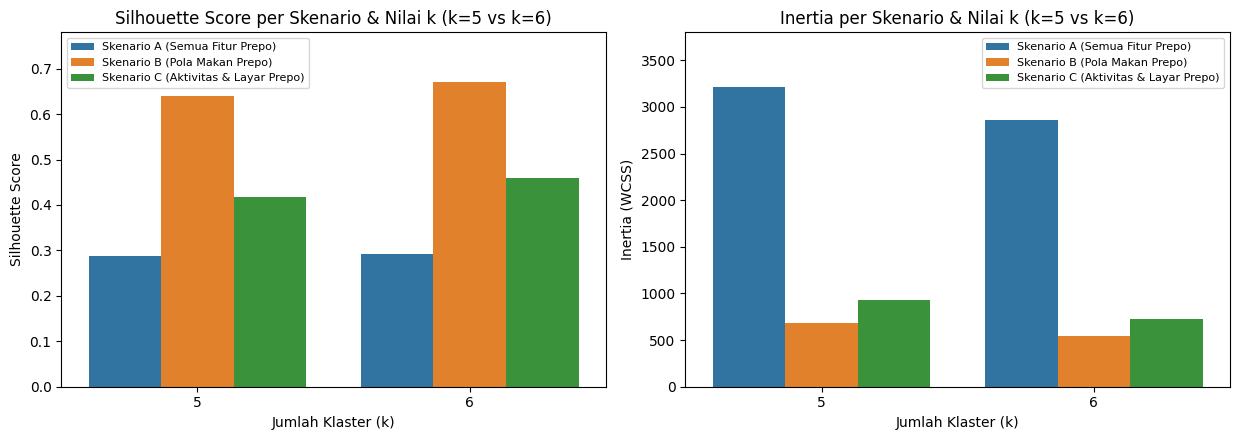

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

sns.barplot(data=df_eksperimen, x='k', y='Silhouette_Score', hue='Skenario', ax=axes[0])
axes[0].set_title('Silhouette Score per Skenario & Nilai k (k=5 vs k=6)')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_xlabel('Jumlah Klaster (k)')
axes[0].set_ylim(0, 0.78)
axes[0].legend(fontsize=8, loc='upper left')

sns.barplot(data=df_eksperimen, x='k', y='Inertia', hue='Skenario', ax=axes[1])
axes[1].set_title('Inertia per Skenario & Nilai k (k=5 vs k=6)')
axes[1].set_ylabel('Inertia (WCSS)')
axes[1].set_xlabel('Jumlah Klaster (k)')
axes[1].set_ylim(0, 3800)
axes[1].legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()


Langkah 6 — Profil & Penamaan Klaster (Skenario A, k = 6)

Pada Skenario A (k = 6), karena kolom numerik sudah terstandarisasi, nilai positif (+) menunjukkan di atas rata-rata dan negatif (-) menunjukkan di bawah rata-rata:

Klaster 0 (453 data): FCVC = -0.85, FAF = -0.42, TUE = -0.86 → "Sayur, Gerak & Layar Rendah"

Klaster 1 (179 data): FCVC = -0.97, FAF = +1.43, TUE = +1.01 → "Sayur Rendah, Gerak & Layar Tinggi"

Klaster 2 (375 data): FCVC = +0.95, FAF = +0.57, TUE = +0.65 → "Sayur & Gerak Tinggi, Layar Menengah"

Klaster 3 (432 data): FCVC = +0.96, FAF = -0.87, TUE = -0.44 → "Sayur Tinggi, Aktivitas Fisik Rendah"

Klaster 4 (361 data): FCVC = -0.86, FAF = -0.65, TUE = +1.14 → "Sayur & Gerak Rendah, Layar Tinggi"

Klaster 5 (287 data): FCVC = +0.35, FAF = +1.15, TUE = -0.88 → "Aktivitas Fisik Tinggi, Layar Rendah"

In [74]:
cols_utama = skenario_prepo['Skenario A (Semua Fitur Prepo)']
_, labels_utama, _ = model_tersimpan[(K_MODEL_UTAMA, 'Skenario A (Semua Fitur Prepo)')]

nama_profil_k6 = {
    0: "Sayur, Gerak & Layar Rendah",
    1: "Sayur Rendah, Gerak & Layar Tinggi",
    2: "Sayur & Gerak Tinggi, Layar Menengah",
    3: "Sayur Tinggi, Aktivitas Fisik Rendah",
    4: "Sayur & Gerak Rendah, Layar Tinggi",
    5: "Aktivitas Fisik Tinggi, Layar Rendah"
}

df_profil = df_pre[cols_utama].copy()
df_profil['Cluster'] = labels_utama
df_profil['Nama_Profil'] = df_profil['Cluster'].map(nama_profil_k6)

display(df_profil.groupby(['Cluster', 'Nama_Profil'])[cols_utama].agg(['count', 'mean']).round(2))

numerik__FCVC       numerik__FAF  \
                                                     count  mean        count   
Cluster Nama_Profil                                                             
0       Sayur, Gerak & Layar Rendah                    453 -0.85          453   
1       Sayur Rendah, Gerak & Layar Tinggi             179 -0.97          179   
2       Sayur & Gerak Tinggi, Layar Menengah           375  0.95          375   
3       Sayur Tinggi, Aktivitas Fisik Rendah           432  0.96          432   
4       Sayur & Gerak Rendah, Layar Tinggi             361 -0.86          361   
5       Aktivitas Fisik Tinggi, Layar Rendah           287  0.35          287   

                                                   numerik__TUE        \
                                              mean        count  mean   
Cluster Nama_Profil                                                     
0       Sayur, Gerak & Layar Rendah          -0.42          453 -0.86   
1       Sayur Rendah, Gerak & Layar Tinggi    1.43          179  1.01   
2       Sayur & Gerak Tinggi, Layar Menengah  0.57          375  0.65   
3       Sayur Tinggi, Aktivitas Fisik Rendah -0.87          432 -0.44   
4       Sayur & Gerak Rendah, Layar Tinggi   -0.65          361  1.14   
5       Aktivitas Fisik Tinggi, Layar Rendah  1.15          287 -0.88   

                                             kategori__FAVC_no        \
                                                         count  mean   
Cluster Nama_Profil                                                    
0       Sayur, Gerak & Layar Rendah                        453  0.11   
1       Sayur Rendah, Gerak & Layar Tinggi                 179  0.15   
2       Sayur & Gerak Tinggi, Layar Menengah               375  0.11   
3       Sayur Tinggi, Aktivitas Fisik Rendah               432  0.09   
4       Sayur & Gerak Rendah, Layar Tinggi                 361  0.09   
5       Aktivitas Fisik Tinggi, Layar Rendah               287  0.19   

                                             kategori__FAVC_yes        \
                                                          count  mean   
Cluster Nama_Profil                                                     
0       Sayur, Gerak & Layar Rendah                         453  0.89   
1       Sayur Rendah, Gerak & Layar Tinggi                  179  0.85   
2       Sayur & Gerak Tinggi, Layar Menengah                375  0.89   
3       Sayur Tinggi, Aktivitas Fisik Rendah                432  0.91   
4       Sayur & Gerak Rendah, Layar Tinggi                  361  0.91   
5       Aktivitas Fisik Tinggi, Layar Rendah                287  0.81   

                                             kategori__CAEC_Always        \
                                                             count  mean   
Cluster Nama_Profil                                                        
0       Sayur, Gerak & Layar Rendah                            453  0.02   
1       Sayur Rendah, Gerak & Layar Tinggi                     179  0.03   
2       Sayur & Gerak Tinggi, Layar Menengah                   375  0.02   
3       Sayur Tinggi, Aktivitas Fisik Rendah                   432  0.02   
4       Sayur & Gerak Rendah, Layar Tinggi                     361  0.04   
5       Aktivitas Fisik Tinggi, Layar Rendah                   287  0.04   

                                             kategori__CAEC_Frequently        \
                                                                 count  mean   
Cluster Nama_Profil                                                            
0       Sayur, Gerak & Layar Rendah                                453  0.06   
1       Sayur Rendah, Gerak & Layar Tinggi                         179  0.15   
2       Sayur & Gerak Tinggi, Layar Menengah                       375  0.11   
3       Sayur Tinggi, Aktivitas Fisik Rendah                       432  0.13   
4       Sayur & Gerak Rendah, Layar Tinggi                         361  0.11   
5       Aktivitas Fisik T

Langkah 7 — Rekap Akhir & Simpan Model Utama (model_varian_3_kmeans.pkl)

Menampilkan tabel rekap seluruh eksperimen Varian 3 dan menyimpan model K-Means utama (Skenario A, semua 9 kolom preprocessing, k = 6) ke berkas model_varian_3_kmeans.pkl.

In [77]:
display(df_eksperimen)

model_utama_v3, _, _ = model_tersimpan[(K_MODEL_UTAMA, 'Skenario A (Semua Fitur Prepo)')]
joblib.dump(model_utama_v3, 'model_varian_3_kmeans.pkl')
print("Model utama Varian 3 (Skenario A, k=6) berhasil disimpan ke 'model_varian_3_kmeans.pkl'")

,k,Skenario,Jumlah_Kolom,Inertia,Silhouette_Score
0,5,Skenario A (Semua Fitur Prepo),9,3210.74,0.2883
1,5,Skenario B (Pola Makan Prepo),7,680.10,0.6391
2,5,Skenario C (Aktivitas & Layar Prepo),2,931.82,0.4174
3,6,Skenario A (Semua Fitur Prepo),9,2857.79,0.2924
4,6,Skenario B (Pola Makan Prepo),7,543.54,0.6703
5,6,Skenario C (Aktivitas & Layar Prepo),2,730.99,0.4583


Model utama Varian 3 (Skenario A, k=6) berhasil disimpan ke 'model_varian_3_kmeans.pkl'
